In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

DATA_DIR = r"C:\Users\minsa_\Downloads"
RANDOM_STATE = 42
LABEL_COLS = ["FECD", "Guttata", "Folds", "PolyPleo", "LowCD"]

ml  = pd.read_csv(os.path.join(DATA_DIR, "Final_Features_MultiLabel.csv"))
tab = pd.read_csv(os.path.join(DATA_DIR, "Tabular_Features.csv"))

CANDIDATES = ["ECD_CD_cells_per_mm2", "ECD_Deficit", "ECD_Age_Residual", "SD", "log_SD", "CV", "HEX_percent",
              "Pleomorphism_Index", "SD_x_CV", "Total_Cell_Count", "Donor_Age", "Death_to_Preservation_Min",
              "Donor_Sex_Male", "Lens_Pseudophakic", "Eye_Right"]

df = ml[["Tissue_ID", "Donor_Group", "Split"] + LABEL_COLS + ["Normal"]].merge(
        tab[["Tissue_ID"] + CANDIDATES], on="Tissue_ID", how="left")
train = df[df["Split"] == "train"].reset_index(drop=True)      # analysis uses TRAIN only

print("Train rows:", len(train))
train[LABEL_COLS].sum().to_frame("Positives in train")

Train rows: 838


,Positives in train
FECD,102
Guttata,81
Folds,306
PolyPleo,106
LowCD,103


In [2]:
def cliffs_delta(a, b):
    return 2 * mannwhitneyu(a, b).statistic / (len(a) * len(b)) - 1

delta, pval, auc1 = {}, {}, {}
for lab in LABEL_COLS:
    d_, p_, a_ = {}, {}, {}
    for f in CANDIDATES:
        pos = train.loc[train[lab] == 1, f].dropna()
        neg = train.loc[train[lab] == 0, f].dropna()
        d_[f] = cliffs_delta(pos, neg)
        p_[f] = mannwhitneyu(pos, neg).pvalue * len(CANDIDATES) * len(LABEL_COLS)   # Bonferroni
        sub = train[[f, lab]].dropna()
        a = roc_auc_score(sub[lab], sub[f]); a_[f] = max(a, 1 - a)
    delta[lab], pval[lab], auc1[lab] = d_, p_, a_

delta = pd.DataFrame(delta).round(2)
pval  = pd.DataFrame(pval).clip(upper=1)
auc1  = pd.DataFrame(auc1).round(3)

print("Cliff's delta: disease present vs absent. |d| <0.15 negligible, <0.33 small, <0.47 medium, >=0.47 large")
display(delta)
print("Single-feature ROC-AUC (0.5 = useless, 1.0 = perfect):")
display(auc1)
print("Significant after Bonferroni (p_adj < 0.05):")
(pval < 0.05).replace({True: "yes", False: ""})

Cliff's delta: disease present vs absent. |d| <0.15 negligible, <0.33 small, <0.47 medium, >=0.47 large


,FECD,Guttata,Folds,PolyPleo,LowCD
ECD_CD_cells_per_mm2,-0.97,-0.16,0.11,-0.97,-0.97
ECD_Deficit,0.97,0.12,-0.09,0.97,0.97
ECD_Age_Residual,-0.96,-0.15,0.14,-0.96,-0.96
SD,0.81,0.12,-0.01,0.81,0.82
log_SD,0.81,0.12,-0.01,0.81,0.82
CV,0.09,-0.04,0.12,0.10,0.11
HEX_percent,-0.05,-0.01,-0.11,-0.07,-0.06
Pleomorphism_Index,0.08,-0.02,0.14,0.09,0.09
SD_x_CV,0.61,0.08,0.04,0.61,0.62
Total_Cell_Count,-0.24,-0.09,-0.04,-0.24,-0.22


Single-feature ROC-AUC (0.5 = useless, 1.0 = perfect):


,FECD,Guttata,Folds,PolyPleo,LowCD
ECD_CD_cells_per_mm2,0.987,0.579,0.554,0.983,0.985
ECD_Deficit,0.987,0.561,0.547,0.983,0.985
ECD_Age_Residual,0.981,0.575,0.572,0.979,0.979
SD,0.907,0.558,0.503,0.905,0.910
log_SD,0.907,0.558,0.503,0.905,0.910
CV,0.547,0.518,0.561,0.548,0.557
HEX_percent,0.525,0.505,0.555,0.536,0.530
Pleomorphism_Index,0.539,0.510,0.568,0.545,0.547
SD_x_CV,0.806,0.538,0.521,0.804,0.811
Total_Cell_Count,0.622,0.546,0.521,0.618,0.612


Significant after Bonferroni (p_adj < 0.05):


,FECD,Guttata,Folds,PolyPleo,LowCD
ECD_CD_cells_per_mm2,yes,,,yes,yes
ECD_Deficit,yes,,,yes,yes
ECD_Age_Residual,yes,,yes,yes,yes
SD,yes,,,yes,yes
log_SD,yes,,,yes,yes
CV,,,,,
HEX_percent,,,,,
Pleomorphism_Index,,,,,
SD_x_CV,yes,,,yes,yes
Total_Cell_Count,yes,,,yes,yes


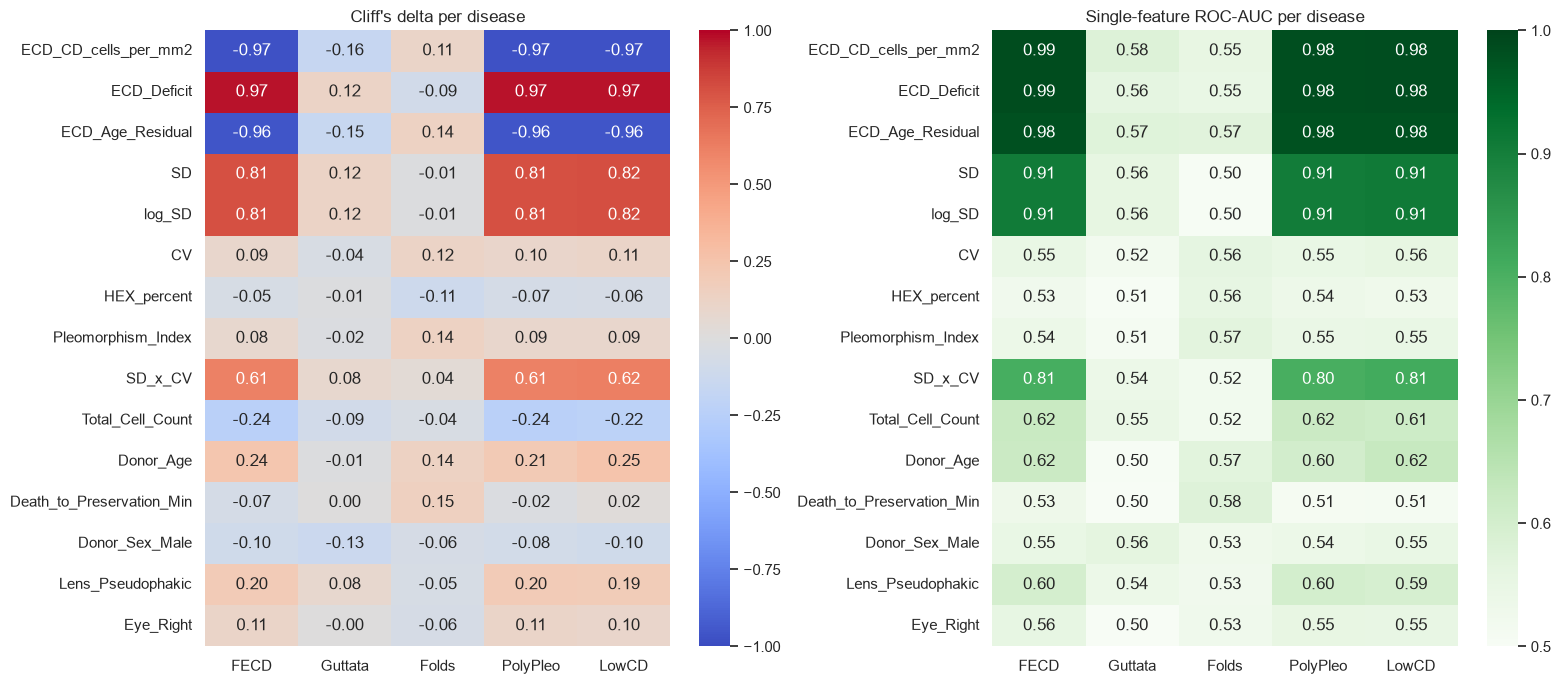

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sns.heatmap(delta, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Cliff's delta per disease")
sns.heatmap(auc1, annot=True, fmt=".2f", cmap="Greens", vmin=0.5, vmax=1, ax=axes[1])
axes[1].set_title("Single-feature ROC-AUC per disease")
plt.tight_layout(); plt.show()

In [4]:
Xi = train[CANDIDATES].fillna(train[CANDIDATES].median())
mi = pd.DataFrame({lab: mutual_info_classif(Xi, train[lab], random_state=RANDOM_STATE) for lab in LABEL_COLS},
                  index=CANDIDATES).round(3)
print("Mutual information per disease (higher = more informative):")
mi

Mutual information per disease (higher = more informative):


,FECD,Guttata,Folds,PolyPleo,LowCD
ECD_CD_cells_per_mm2,0.283,0.007,0.036,0.278,0.282
ECD_Deficit,0.283,0.008,0.007,0.278,0.281
ECD_Age_Residual,0.245,0.001,0.022,0.249,0.245
SD,0.152,0.007,0.019,0.152,0.162
log_SD,0.147,0.002,0.045,0.144,0.156
CV,0.006,0.000,0.007,0.006,0.008
HEX_percent,0.020,0.003,0.035,0.017,0.014
Pleomorphism_Index,0.000,0.011,0.014,0.000,0.000
SD_x_CV,0.096,0.006,0.000,0.097,0.105
Total_Cell_Count,0.035,0.034,0.018,0.038,0.035


Permutation importance per disease (drop in ROC-AUC):


,FECD,Guttata,Folds,PolyPleo,LowCD
ECD_CD_cells_per_mm2,0.0605,0.0283,0.0202,0.0525,0.0586
ECD_Deficit,0.0210,0.0169,0.0074,0.0193,0.0103
SD,0.0028,0.0210,-0.0020,0.0086,0.0067
CV,0.0009,0.0291,0.0067,0.0027,-0.0012
HEX_percent,0.0007,0.0035,0.0080,0.0000,0.0008
Pleomorphism_Index,0.0016,0.0199,0.0217,0.0013,0.0012
Total_Cell_Count,0.0022,0.0047,0.0043,0.0021,0.0002
Donor_Age,0.0004,-0.0129,0.0390,0.0026,-0.0011
Death_to_Preservation_Min,0.0001,0.0172,0.0093,0.0016,-0.0014
Donor_Sex_Male,0.0037,0.0117,0.0006,0.0056,0.0007


Numbers-only ROC-AUC per disease (donor-grouped CV):


,CV ROC-AUC
FECD,0.987
Guttata,0.599
Folds,0.649
PolyPleo,0.981
LowCD,0.973


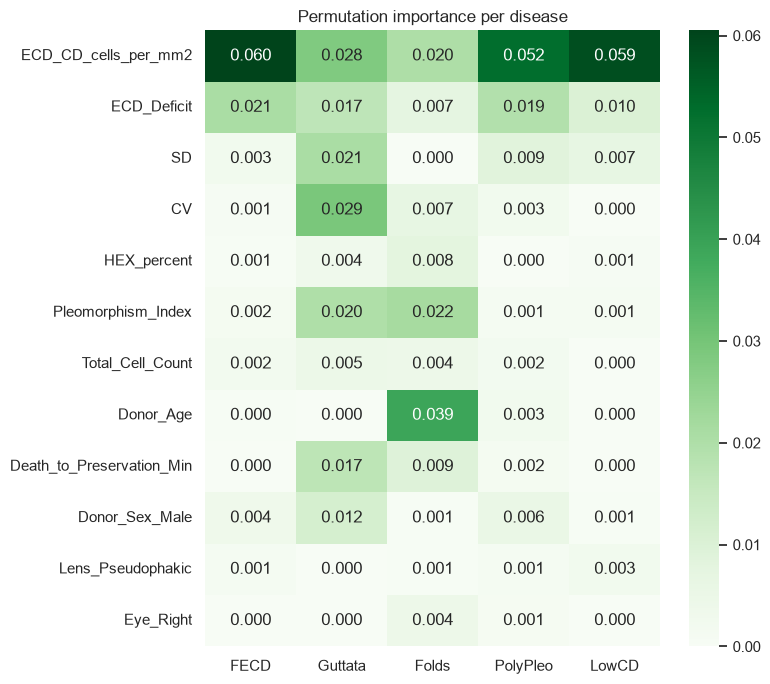

In [5]:
REDUNDANT = ["log_SD", "SD_x_CV", "ECD_Age_Residual"]          # near-copies of SD / ECD
MODEL_FEATS = [f for f in CANDIDATES if f not in REDUNDANT]
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def rf():
    return Pipeline([("imp", SimpleImputer(strategy="median")),
                     ("rf", RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                                   class_weight="balanced_subsample",
                                                   random_state=RANDOM_STATE, n_jobs=-1))])

perm, cv_auc = {}, {}
for lab in LABEL_COLS:
    imps, y_true, y_prob = [], [], []
    for tr, va in cv.split(train, train[lab], groups=train["Donor_Group"]):
        m = rf().fit(train.iloc[tr][MODEL_FEATS], train.iloc[tr][lab])
        pi = permutation_importance(m, train.iloc[va][MODEL_FEATS], train.iloc[va][lab], scoring="roc_auc",
                                    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
        imps.append(pi.importances_mean)
        y_true += list(train.iloc[va][lab])
        y_prob += list(m.predict_proba(train.iloc[va][MODEL_FEATS])[:, 1])
    perm[lab] = np.mean(imps, axis=0)
    cv_auc[lab] = roc_auc_score(y_true, y_prob)

perm = pd.DataFrame(perm, index=MODEL_FEATS).round(4)
print("Permutation importance per disease (drop in ROC-AUC):")
display(perm)
print("Numbers-only ROC-AUC per disease (donor-grouped CV):")
display(pd.Series(cv_auc).round(3).to_frame("CV ROC-AUC"))

plt.figure(figsize=(8, 7))
sns.heatmap(perm.clip(lower=0), annot=True, fmt=".3f", cmap="Greens")
plt.title("Permutation importance per disease"); plt.tight_layout(); plt.show()

In [6]:
def level(lab, f):
    d, a, p = abs(delta.loc[f, lab]), auc1.loc[f, lab], perm.loc[f, lab]
    if (d >= 0.33 or a >= 0.65) and p > 0.005: return "Strong"
    if (d >= 0.15 or a >= 0.58) and pval.loc[f, lab] < 0.05: return "Weak"
    return "-"

verdict = pd.DataFrame({lab: {f: level(lab, f) for f in MODEL_FEATS} for lab in LABEL_COLS})
verdict["Useful for"] = verdict.apply(lambda r: ", ".join([l for l in LABEL_COLS if r[l] != "-"]) or "none", axis=1)
verdict

,FECD,Guttata,Folds,PolyPleo,LowCD,Useful for
ECD_CD_cells_per_mm2,Strong,-,-,Strong,Strong,"FECD, PolyPleo, LowCD"
ECD_Deficit,Strong,-,-,Strong,Strong,"FECD, PolyPleo, LowCD"
SD,Weak,-,-,Strong,Strong,"FECD, PolyPleo, LowCD"
CV,-,-,-,-,-,none
HEX_percent,-,-,-,-,-,none
Pleomorphism_Index,-,-,-,-,-,none
Total_Cell_Count,Weak,-,-,Weak,Weak,"FECD, PolyPleo, LowCD"
Donor_Age,Weak,-,-,Weak,Weak,"FECD, PolyPleo, LowCD"
Death_to_Preservation_Min,-,-,-,-,-,none
Donor_Sex_Male,-,-,-,-,-,none


In [7]:
CURRENT_6 = ["ECD_CD_cells_per_mm2", "ECD_Deficit", "SD", "CV", "HEX_percent", "Donor_Age"]

def cv_auc_for(cols, lab):
    p = cross_val_predict(rf(), train[cols], train[lab], cv=cv, groups=train["Donor_Group"],
                          method="predict_proba")[:, 1]
    return roc_auc_score(train[lab], p)

comp = pd.DataFrame({lab: {"Current 6 features": cv_auc_for(CURRENT_6, lab),
                           f"All {len(MODEL_FEATS)} features": cv_auc_for(MODEL_FEATS, lab)}
                     for lab in LABEL_COLS}).round(3)
print("Donor-grouped CV ROC-AUC per disease:")
comp

Donor-grouped CV ROC-AUC per disease:


,FECD,Guttata,Folds,PolyPleo,LowCD
Current 6 features,0.981,0.582,0.621,0.964,0.969
All 12 features,0.987,0.599,0.649,0.981,0.973
